<a href="https://colab.research.google.com/github/ElvisC1023746/PLN-ANALISIS-DE-SENTIMIENTOS-APPLE/blob/main/Proyecto3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

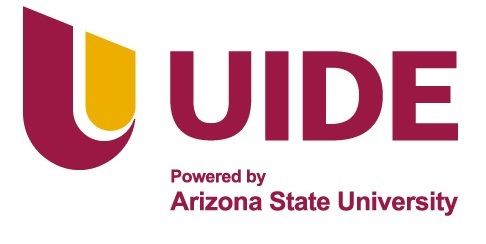

# PROYECTO INTEGRADOR DE SISTEMA IA APLICADA PARA ANÁLISIS PREDICTIVO

PROCESAMIENTO DE LENGUAJE NATURAL - ANÁLISIS DE SENTIMIENTOS EN CONSUMIDORES PRODUCTOS APPLE

Elaborado por Elvis Cóndor

4/11/2026


# Importación de Librerías

In [1]:
import re
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline

# Cargar Bases de Datos

In [2]:
df = pd.read_excel('AppleBD.xlsx')
print("Shape original:", df.shape)
print(df.head())

df = df[['Etiqueta', 'Sentimientos']].dropna()
print("Shape tras selección y limpieza de nulos:", df.shape)

print("\nDistribución de clases:")
print(df['Etiqueta'].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'AppleBD.xlsx'

# Transformación de Etiquetas a Target Numérico

In [ ]:
target_map = {'Positivo': 1, 'Negativo': -1, 'Neutral': 0}
df['target'] = df['Etiqueta'].map(target_map)

if df['target'].isnull().any():
    print("Advertencia: hay etiquetas no mapeadas. Se eliminarán.")
    print(df[df['target'].isnull()]['Etiqueta'].unique())
    df = df.dropna(subset=['target'])

df['target'] = df['target'].astype(int)

# Procesamiento de Texto

In [ ]:
def limpiar_texto(texto):
    if not isinstance(texto, str):
        return ""
    texto = texto.lower()
    texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)
    texto = re.sub(r'@\w+|#\w+', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

df['texto_limpio'] = df['Sentimientos'].apply(limpiar_texto)

print("\nEjemplo de texto original vs. limpio:")
for i in range(3):
    print("  ORIGINAL:", df['Sentimientos'].iloc[i])
    print("  LIMPIO  :", df['texto_limpio'].iloc[i])
    print()

# Balance de Datos Train/Test

In [ ]:
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['target']
)

print("Train:", df_train.shape, "| Test:", df_test.shape)
print("Distribución en train:\n", df_train['target'].value_counts(normalize=True))
print("Distribución en test:\n", df_test['target'].value_counts(normalize=True))

X_train_text = df_train['texto_limpio'].tolist()
X_test_text = df_test['texto_limpio'].tolist()
Y_train = df_train['target']
Y_test = df_test['target']

# Generación de Embeddings para Multi - Lenguaje

In [ ]:
print("\nCargando modelo de embeddings multilingüe...")
embedder = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')

print("Generando embeddings para train...")
X_train_emb = embedder.encode(X_train_text, show_progress_bar=True)

print("Generando embeddings para test...")
X_test_emb = embedder.encode(X_test_text, show_progress_bar=True)

print("Shape embeddings train:", X_train_emb.shape)
print("Shape embeddings test:", X_test_emb.shape)

# Búsqueda de Hiperparámetros Mediante Validación Cruzada

In [ ]:
pipeline = Pipeline([
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

parametros = {
    'clf__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    pipeline,
    parametros,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

print("\nEjecutando GridSearchCV sobre embeddings...")
grid.fit(X_train_emb, Y_train)

print("\nMejores parámetros:", grid.best_params_)
print("Mejor F1 Macro (CV):", round(grid.best_score_, 4))

# Evaluación del Mejor Modelo para Mayor Precisión

In [ ]:
best_model = grid.best_estimator_

P_train = best_model.predict(X_train_emb)
P_test = best_model.predict(X_test_emb)

print("\n--- MÉTRICAS EN TRAIN ---")
print("Accuracy:", round(accuracy_score(Y_train, P_train), 4))
print("F1 Macro:", round(f1_score(Y_train, P_train, average='macro'), 4))
print(classification_report(Y_train, P_train, target_names=['Negativo', 'Neutral', 'Positivo']))

print("\n--- MÉTRICAS EN TEST ---")
print("Accuracy:", round(accuracy_score(Y_test, P_test), 4))
print("F1 Macro:", round(f1_score(Y_test, P_test, average='macro'), 4))
print(classification_report(Y_test, P_test, target_names=['Negativo', 'Neutral', 'Positivo']))

# Matrices de Confusión


In [ ]:
def plot_cm(cm, titulo):
    classes = ['Negativo', 'Neutral', 'Positivo']
    df_cm = pd.DataFrame(cm, index=classes, columns=classes)
    plt.figure(figsize=(6, 5))
    sn.heatmap(df_cm, annot=True, fmt='.2f', cmap='Blues')
    plt.xlabel('Predicción')
    plt.ylabel('Objetivo')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

cm_train = confusion_matrix(Y_train, P_train, normalize='true', labels=[-1, 0, 1])
plot_cm(cm_train, 'Matriz de Confusión - Train')

cm_test = confusion_matrix(Y_test, P_test, normalize='true', labels=[-1, 0, 1])
plot_cm(cm_test, 'Matriz de Confusión - Test')

# Predicción con Textos Nuevos

In [ ]:
nombre_clase = {-1: 'Negativo', 0: 'Neutral', 1: 'Positivo'}

textos_prueba = {
    "Inglés": [
        "My iPhone heats up a lot and the battery drains incredibly fast",
        "Excellent product, the camera is amazing and performance is perfect",
        "The device arrived in good condition, it is a normal product",
        "The touch screen stopped working, very disappointed with Apple"
    ],
    "Español": [
        "El iPhone se calienta mucho y la batería se agota rapidísimo",
        "Excelente producto, la cámara es increíble y el rendimiento perfecto",
        "El equipo llegó en buen estado, es un producto normal",
        "No funciona el touch, muy decepcionado con Apple"
    ]
}

for idioma, lista_textos in textos_prueba.items():
    print(f"\n--- PREDICCIONES SOBRE TEXTOS NUEVOS ({idioma}) ---")
    textos_limpios = [limpiar_texto(t) for t in lista_textos]
    embeddings = embedder.encode(textos_limpios, show_progress_bar=False)
    predicciones = best_model.predict(embeddings)
    probabilidades = best_model.predict_proba(embeddings)

    for texto, pred, probs in zip(lista_textos, predicciones, probabilidades):
        print(f"\nTexto: {texto}")
        print(f"Predicción: {nombre_clase[pred]}")
        print(f"Probabilidades: Neg={probs[0]:.3f}, Neu={probs[1]:.3f}, Pos={probs[2]:.3f}")